# Chia tập và baseline model

Model được chạy sau khi dữ liệu đã gộp. Cùng một group split được dùng cho mọi model; risk=1 là Fail hoặc Withdrawn.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists() and (ROOT.parent / 'clht_code').exists():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
DATA=ROOT/'data'
OUT=ROOT/'ket_qua'
OUT.mkdir(exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
from clht_code.data import create_asof
from clht_code.models import configs,feature_columns
from clht_code.evaluation import split_groups,assert_disjoint,fit_score
frame=create_asof(DATA,0.5,'fraction','strict'); cols=feature_columns(frame); X=frame[cols]; y=frame.risk.astype(int).to_numpy(); train,val,test=split_groups(frame,42); assert_disjoint(frame,[train,val,test]); print(frame.shape,[len(x) for x in [train,val,test]])

(24599, 34) [17204, 3699, 3696]


,average_precision_risk,recall_risk,weighted_f1
model,,,
HistGradientBoosting,0.842388,0.625090,0.803212
RandomForest,0.838294,0.625329,0.799514
ExtraTrees,0.835589,0.655914,0.801599
LogisticRegression,0.833900,0.721147,0.791461
DecisionTree,0.798309,0.702987,0.774024


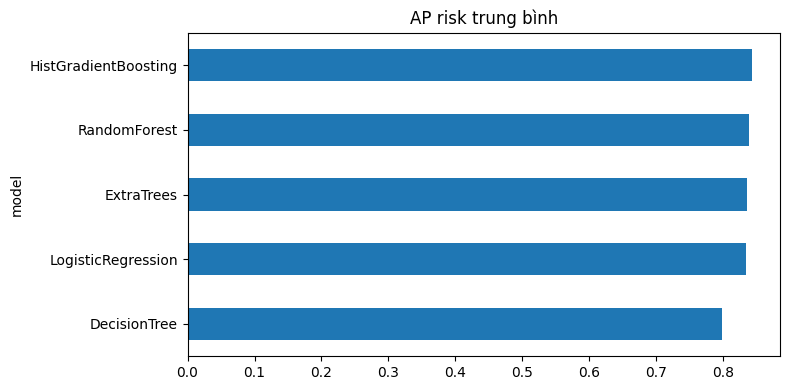

In [2]:
records=[]
for seed in [41,77,123]:
 for cfg in configs(seed):
  pipe,m=fit_score(X.iloc[train],y[train],X.iloc[val],y[val],cfg)
  records.append({'model':cfg.name,'seed':seed,**{k:v for k,v in m.items() if k!='model'}})
base=pd.DataFrame(records); base.to_csv(OUT/'ket_qua_mo_hinh_co_so.csv',index=False,encoding='utf-8-sig'); display(base.groupby('model')[['average_precision_risk','recall_risk','weighted_f1']].mean().sort_values('average_precision_risk',ascending=False))
fig,ax=plt.subplots(figsize=(8,4)); base.groupby('model').average_precision_risk.mean().sort_values().plot.barh(ax=ax,title='AP risk trung bình'); fig.tight_layout(); fig.savefig(OUT/'ap_mo_hinh_co_so.png',dpi=150); plt.show()

## Nhận xét

HGB phù hợp khi ưu tiên xếp hạng risk; Logistic Regression cần giữ lại nếu ưu tiên recall. Đây là baseline để HCO/VNLS có mốc so sánh.

## Đánh giá test sau khi khóa ứng viên

Validation dùng để chọn; test chỉ được đọc sau đó. Giữ HGB và Logistic Regression vì chúng đại diện cho hai mục tiêu khác nhau.

In [3]:
selected=['HistGradientBoosting','LogisticRegression']
final=[]
for name in selected:
 cfg=[c for c in configs(41) if c.name==name][0]
 train_val=pd.concat([X.iloc[train],X.iloc[val]])
 y_train_val=pd.concat([pd.Series(y[train]),pd.Series(y[val])]).to_numpy()
 pipe,m=fit_score(train_val,y_train_val,X.iloc[test],y[test],cfg)
 final.append({'model':name,**{k:v for k,v in m.items() if k!='model'}})
final_test=pd.DataFrame(final); final_test.to_csv(OUT/'ket_qua_test_cuoi.csv',index=False,encoding='utf-8-sig'); display(final_test)

,model,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,roc_auc,brier_score,tn,fp,fn,tp,alerts,n,threshold
0,HistGradientBoosting,0.817370,0.846380,0.625452,0.719335,0.810274,0.852868,0.878468,0.128190,2156,157,518,865,1022,3696,0.5
1,LogisticRegression,0.803301,0.740469,0.730296,0.735348,0.803023,0.841500,0.870733,0.140189,1959,354,373,1010,1364,3696,0.5
